# Partie 5 : extension générative, option B (VAE)

Un auto-encodeur variationnel (VAE) ressemble à l'auto-encodeur de la partie 3, avec une différence : pour chaque image, l'encodeur ne donne pas un point mais une **distribution** (une moyenne $\mu$ et une variance $\sigma^2$). On tire $z$ dans cette distribution, puis le décodeur reconstruit l'image. L'espace latent devient continu : on peut s'y déplacer et générer de nouvelles images.

Ce qui est demandé :

- entraîner un VAE 64×64 ;
- visualiser l'espace latent en 2D, coloré par classe ;
- faire des interpolations entre deux feuilles ;
- générer de nouvelles images ;
- comparer l'erreur de reconstruction et l'ELBO du VAE à l'auto-encodeur simple comme score d'anomalie.

On a choisi l'option B car elle prolonge directement la partie 3 et elle est plus stable à entraîner qu'un GAN.

- On ajoute le dossier du projet au chemin Python pour importer notre code (`src/`).
- `config` contient les chemins, la classe M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard : on obtient les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée (à noter dans le rapport).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # dossier du projet, pour pouvoir importer src/

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- Mêmes réglages que la partie 3 : images 64×64, pixels entre 0 et 1, pas de normalisation.
- On relit le k de l'auto-encodeur de la partie 3 (`thresholds_ae.json`), pour comparer à armes égales à la fin.
- Pour visualiser l'espace latent, le premier VAE est entraîné sur **toutes** les classes du train (sans leurs étiquettes).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.manifold import TSNE

from src import data as D
from src import viz
from src.models import VAE, build_ae
from src.train import fit_recon, recon_errors
from src.metrics import detection_metrics, upsert_summary, count_params, model_size_mb, savefig

df = D.load_splits()
seuils_ae = C.load_json(C.RESULTS / "thresholds_ae.json")
K = seuils_ae["k"]


def creer_loader(donnees, train=False):
    ds = D.LeafDataset(donnees, 64, D.get_transform("ae", train), D.CLASSES)
    return D.make_loader(ds, 64, shuffle=train)


loaders_tout = {"train": creer_loader(D.subset(df, split="train"), train=True),
                "val": creer_loader(D.subset(df, split="val"))}
print("Images d'entraînement :", len(loaders_tout["train"].dataset))

Images d'entraînement : 12711


## Entraînement du VAE

- **Architecture** : la même que l'auto-encodeur de la partie 3 (3 convolutions F=4, S=2, P=1 : 64 → 32 → 16 → 8), mais la couche dense finale donne deux vecteurs, $\mu$ et $\log \sigma^2$, au lieu d'un seul code.
- **Reparamétrisation** : $z = \mu + \sigma \times \varepsilon$ avec $\varepsilon$ tiré au hasard. Le hasard est mis à part dans $\varepsilon$, ce qui permet au gradient de passer par $\mu$ et $\sigma$.
- **Perte** = erreur de reconstruction + β × KL. Le terme KL pousse chaque distribution à rester proche d'une loi normale $\mathcal{N}(0, I)$. L'espace latent devient continu et « sans trous » : un point tiré au hasard se décode en une feuille plausible.
- **Montée de β** : β passe de 0 à 1 pendant les 10 premières époques. Sinon, le terme KL domine au début et le modèle apprend à ignorer $z$.

- VAE avec un espace latent de dimension 32, entraîné 30 époques avec Adam (LR 0,001), batch de 64.
- On recharge les poids de l'époque où la perte de validation est la plus basse.
- Trois courbes : la reconstruction, le terme KL et β. Si le KL tombait à 0, le modèle n'utiliserait plus $z$.

[vae_tout] ep 1/30 | train 524.69863 | val 183.74421 (MSE 0.00765) | 4s
[vae_tout] ep 5/30 | train 114.80740 | val 130.65635 (MSE 0.00653) | 3s
[vae_tout] ep 10/30 | train 128.08102 | val 115.59147 (MSE 0.00671) | 3s
[vae_tout] ep 15/30 | train 122.84864 | val 111.89844 (MSE 0.00659) | 3s
[vae_tout] ep 20/30 | train 120.24019 | val 107.58547 (MSE 0.00620) | 3s
[vae_tout] ep 25/30 | train 119.49073 | val 106.30351 (MSE 0.00606) | 3s
[vae_tout] ep 30/30 | train 117.14828 | val 104.70742 (MSE 0.00603) | 3s


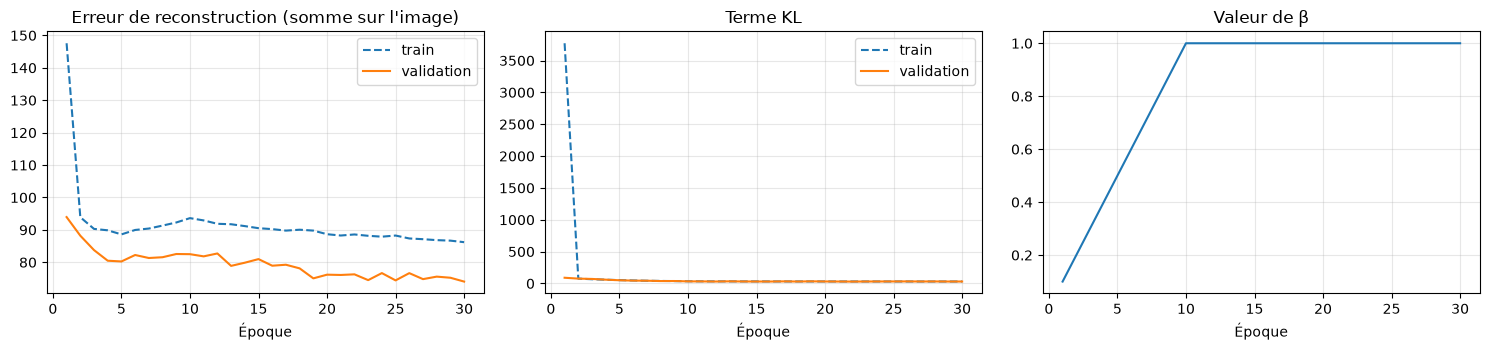

Temps d'entraînement : 84.6 s


In [3]:
C.set_seed(42)
vae = VAE(32).to(C.DEVICE)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
h = fit_recon(vae, loaders_tout, C.ep(30), optimizer, "vae_tout", {"type": "vae", "k": 32, "size": 64},
              vae=True, beta_max=1.0, warmup_epochs=10)
meilleur = torch.load(C.CKPT_DIR / "vae_tout" / "best.pt", map_location=C.DEVICE, weights_only=False)
vae.load_state_dict(meilleur["model"])
vae.eval()

plt.figure(figsize=(15, 3.6))
plt.subplot(1, 3, 1)
plt.plot(h["epoch"], h["train_rec"], "--", label="train")
plt.plot(h["epoch"], h["val_loss"] - h["val_kl"], label="validation")
plt.title("Erreur de reconstruction (somme sur l'image)")
plt.xlabel("Époque")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(h["epoch"], h["train_kl"], "--", label="train")
plt.plot(h["epoch"], h["val_kl"], label="validation")
plt.title("Terme KL")
plt.xlabel("Époque")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(h["epoch"], h["beta"])
plt.title("Valeur de β")
plt.xlabel("Époque")
plt.grid(alpha=0.3)

plt.tight_layout()
savefig("05_vae_courbes.png")
plt.show()
print("Temps d'entraînement :", round(h["train_time_s"].iloc[-1], 1), "s")

## Espace latent en 2D

- On prend au plus 200 images de validation par classe.
- Pour chaque image, on garde la moyenne $\mu$ donnée par l'encodeur (32 valeurs).
- t-SNE ramène ces 32 valeurs à 2 pour pouvoir les dessiner. Chaque point est une image, la couleur est sa classe.
- Le VAE n'a jamais vu les étiquettes. Si des groupes de couleur apparaissent, c'est qu'il a appris tout seul des différences visuelles entre maladies.

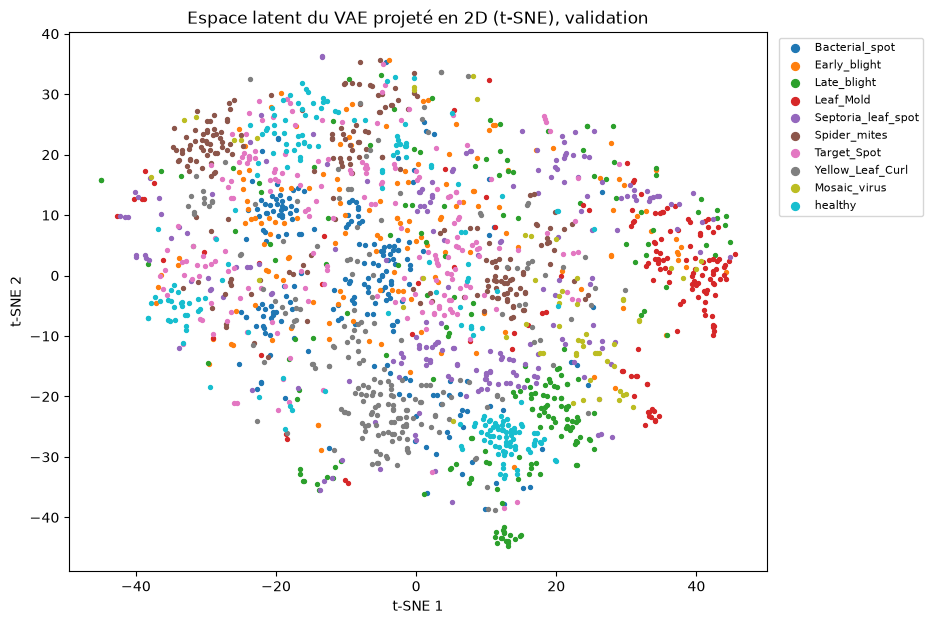

In [4]:
val = D.subset(df, split="val")
morceaux = []
for classe in D.CLASSES:
    images_classe = val[val["class"] == classe]
    morceaux.append(images_classe.sample(min(len(images_classe), 200), random_state=42))
echantillon = pd.concat(morceaux).reset_index(drop=True)

moyennes = []
with torch.no_grad():
    for x, _ in creer_loader(echantillon):
        mu, _ = vae.encode(x.to(C.DEVICE))
        moyennes.append(mu.cpu())
moyennes = torch.cat(moyennes).numpy()

points = TSNE(n_components=2, perplexity=30, random_state=42, init="pca").fit_transform(moyennes)

plt.figure(figsize=(9, 7))
for i in range(len(D.CLASSES)):
    classe = D.CLASSES[i]
    garde = (echantillon["class"] == classe).values
    plt.scatter(points[garde, 0], points[garde, 1], s=8, color=plt.cm.tab10(i), label=D.short(classe))
plt.legend(fontsize=8, markerscale=2, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Espace latent du VAE projeté en 2D (t-SNE), validation")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
savefig("05_tsne.png")
plt.show()

## Interpolations et génération

- On encode deux feuilles (une saine et une malade), puis on décode 8 points régulièrement espacés sur le segment qui relie leurs codes : $z = (1 - t) \, z_a + t \, z_b$.
- Première et dernière colonne : les vraies images. Si l'image change petit à petit entre les deux, l'espace latent est bien continu.

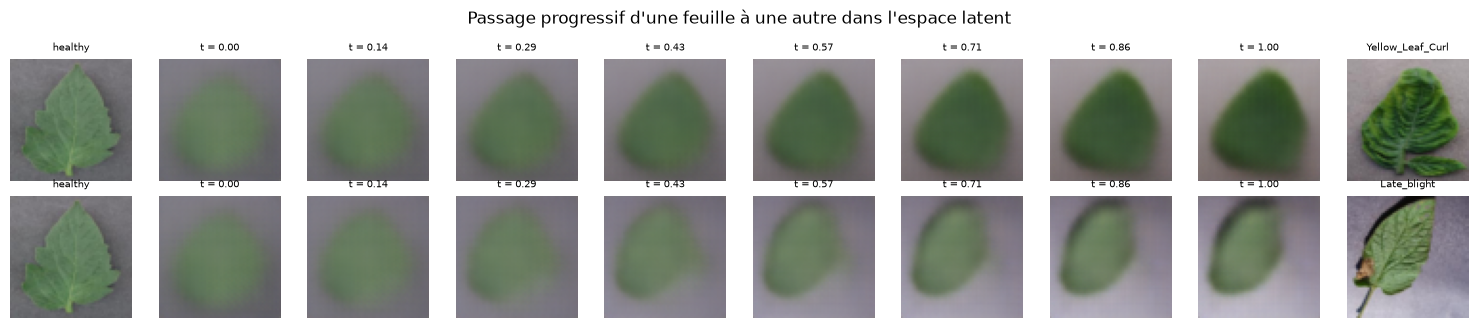

In [5]:
def image_de(classe):
    """Première image de validation de cette classe, sous forme de tenseur 1×3×64×64."""
    positions = np.where(val["class"].values == classe)[0]
    x = loaders_tout["val"].dataset[int(positions[0])][0]
    return x.unsqueeze(0).to(C.DEVICE)


paires = [(C.HEALTHY_CLASS, "Tomato___Tomato_Yellow_Leaf_Curl_Virus"),
          (C.HEALTHY_CLASS, "Tomato___Late_blight")]
images = []
titres = []
with torch.no_grad():
    for paire in paires:
        a = paire[0]
        b = paire[1]
        xa = image_de(a)
        xb = image_de(b)
        za = vae.encode(xa)[0]
        zb = vae.encode(xb)[0]
        images.append(viz.chw_to_img(xa[0]))
        titres.append(D.short(a))
        for t in np.linspace(0, 1, 8):
            z = (1 - t) * za + t * zb
            images.append(viz.chw_to_img(vae.decoder(z)[0]))
            titres.append(f"t = {t:.2f}")
        images.append(viz.chw_to_img(xb[0]))
        titres.append(D.short(b))

viz.image_grid(images, titres, ncols=10, size=1.5, path=C.FIG_DIR / "05_interpolations.png",
               suptitle="Passage progressif d'une feuille à une autre dans l'espace latent")

- Génération : on tire 16 vecteurs $z$ au hasard dans $\mathcal{N}(0, I)$ et on les décode, sans partir d'aucune image.
- On s'attend à des images plausibles mais floues : la perte MSE fait une moyenne des détails incertains.

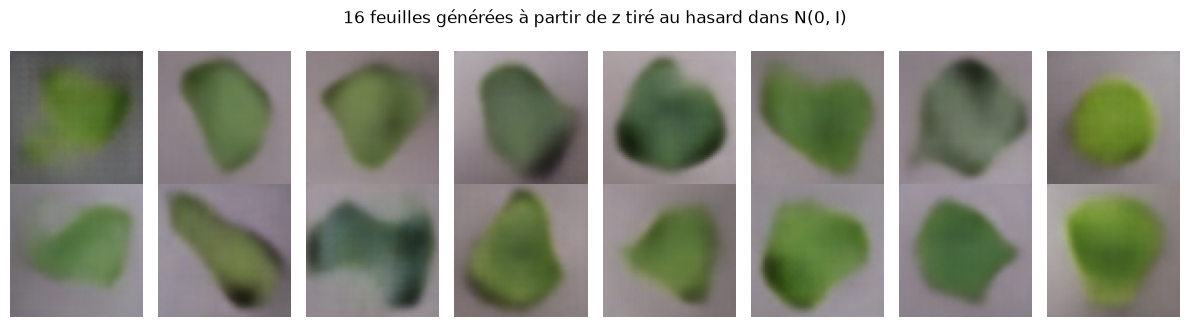

In [6]:
torch.manual_seed(42)
with torch.no_grad():
    nouvelles = vae.sample(16)

images_generees = []
for x in nouvelles:
    images_generees.append(viz.chw_to_img(x))
viz.image_grid(images_generees, None, ncols=8, size=1.5, path=C.FIG_DIR / "05_generation.png",
               suptitle="16 feuilles générées à partir de z tiré au hasard dans N(0, I)")

### Ce qu'on observe

- **Courbes.** Le terme KL chute très vite (environ 3 700 à la première époque, puis autour de 30) mais ne tombe jamais à 0 : le VAE utilise bien son code $z$. Pendant la montée de β (époques 1 à 10), l'erreur de reconstruction du train remonte un peu, de 88 à 94 : c'est le compromis attendu entre bien reconstruire et garder un espace latent régulier. Ensuite elle redescend doucement. La validation est plus basse que le train, parce qu'en évaluation on décode directement $\mu$, sans le bruit de la reparamétrisation.
- **Espace latent (t-SNE).** Sans jamais voir les étiquettes, le VAE regroupe en partie les classes : Leaf_Mold forme un groupe net à droite, Spider_mites en haut à gauche, Yellow_Leaf_Curl et une partie des feuilles saines en bas au centre, et un petit paquet de Late_blight tout en bas. Mais Early_blight, Target_Spot et Septoria sont mélangées au milieu : ce sont des maladies à petites taches brunes, que le code ne distingue pas. Les feuilles saines forment deux groupes séparés, ce qui rejoint les deux modes vus dans les histogrammes de la partie 3 (feuilles claires sur fond uni et feuilles plus sombres ou ombrées).
- **Interpolations.** Le passage d'une feuille à l'autre est régulier : pas de saut ni d'image absurde au milieu, donc l'espace latent est bien continu. Mais ce qui change, c'est surtout la couleur (vert clair vers vert foncé), la forme et la clarté du fond. Les taches et les nervures n'apparaissent jamais. Même à t = 0, la reconstruction de la feuille saine est très floue par rapport à l'originale.
- **Génération.** Les 16 images tirées au hasard ressemblent toutes à « une forme verte sur un fond gris-violet de laboratoire » : c'est plausible, mais sans nervures, sans dentelure ni lésion. Le VAE a surtout appris la couleur de la feuille et le fond. C'est la limite connue du VAE avec une perte MSE : il fait la moyenne des détails incertains, d'où le flou.

## Comparaison avec l'auto-encodeur simple pour détecter les anomalies

Même protocole que la partie 3 : on entraîne un VAE **sur les feuilles saines seulement**, avec le même k que l'auto-encodeur de la partie 3, on fixe le seuil au percentile 95 des saines de validation, puis on évalue sur le test. On compare trois scores :

- l'erreur de reconstruction de l'auto-encodeur simple de la partie 3 ;
- l'erreur de reconstruction du VAE ;
- −ELBO = reconstruction + KL. Une feuille malade peut aussi avoir un code latent loin de ceux des feuilles saines : le terme KL le mesure.

- Second VAE, entraîné seulement sur les feuilles saines du train, avec k = 16 comme l'auto-encodeur de la partie 3, 40 époques comme lui.
- On recharge aussi l'auto-encodeur simple de la partie 3 (`ae_best.pt`).

In [7]:
saines_train = D.subset(df, split="train", classes=[C.HEALTHY_CLASS])
saines_val = D.subset(df, split="val", classes=[C.HEALTHY_CLASS])
loaders_saines = {"train": creer_loader(saines_train, train=True), "val": creer_loader(saines_val)}

C.set_seed(42)
vae_sain = VAE(K).to(C.DEVICE)
optimizer = torch.optim.Adam(vae_sain.parameters(), lr=1e-3)
h_sain = fit_recon(vae_sain, loaders_saines, C.ep(40), optimizer, "vae_sain",
                   {"type": "vae", "k": K, "size": 64}, vae=True, warmup_epochs=10)
meilleur = torch.load(C.CKPT_DIR / "vae_sain" / "best.pt", map_location=C.DEVICE, weights_only=False)
vae_sain.load_state_dict(meilleur["model"])
vae_sain.eval()

# auto-encodeur simple de la partie 3
ae_sain = build_ae(K).to(C.DEVICE)
ae_sain.load_state_dict(torch.load(C.CKPT_DIR / "ae_best.pt", map_location=C.DEVICE))
ae_sain.eval()

[vae_sain] ep 1/40 | train 274.49803 | val 226.16753 (MSE 0.01759) | 0s
[vae_sain] ep 5/40 | train 128.43656 | val 137.48832 (MSE 0.00887) | 0s
[vae_sain] ep 10/40 | train 126.95194 | val 120.70467 (MSE 0.00826) | 0s
[vae_sain] ep 15/40 | train 121.48294 | val 115.29566 (MSE 0.00788) | 0s
[vae_sain] ep 20/40 | train 118.49512 | val 112.56021 (MSE 0.00772) | 0s
[vae_sain] ep 25/40 | train 117.33277 | val 111.44681 (MSE 0.00773) | 0s
[vae_sain] ep 30/40 | train 115.17362 | val 109.84727 (MSE 0.00751) | 0s
[vae_sain] ep 35/40 | train 114.15133 | val 108.48173 (MSE 0.00742) | 0s
[vae_sain] ep 40/40 | train 114.04754 | val 109.72158 (MSE 0.00737) | 0s


Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=8192, out_features=16, bias=True)
  )
  (1): Sequential(
    (0): Linear(in_features=16, out_features=8192, bias=True)
    (1): Unflatten(dim=1, unflattened_size=(128, 8, 8))
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4):

- Pour chaque score : seuil au percentile 95 des feuilles saines de validation, puis AUROC, rappel des maladies et fausses alarmes sur le test. Le test ne sert qu'ici.
- La ligne « AE simple » doit retrouver à peu près les chiffres de la partie 3 (AUROC test 0,628) : c'est une vérification que tout est calculé de la même façon.
- Les deux lignes du VAE vont dans `summary.csv`.

In [8]:
val_tout = D.subset(df, split="val")
test_tout = D.subset(df, split="test")
malade_val = (val_tout["class"] != C.HEALTHY_CLASS).values
malade_test = (test_tout["class"] != C.HEALTHY_CLASS).values
loader_val = creer_loader(val_tout)
loader_test = creer_loader(test_tout)

vae_val = recon_errors(vae_sain, loader_val, vae=True)
vae_test = recon_errors(vae_sain, loader_test, vae=True)

scores = {}
scores["AE simple (partie 3)"] = (recon_errors(ae_sain, loader_val)["err"], recon_errors(ae_sain, loader_test)["err"])
scores["VAE : erreur de reconstruction"] = (vae_val["err"], vae_test["err"])
scores["VAE : -ELBO"] = (vae_val["neg_elbo"], vae_test["neg_elbo"])

lignes = {}
for nom in scores:
    s_val = scores[nom][0]
    s_test = scores[nom][1]
    seuil = np.quantile(s_val[~malade_val], 0.95)
    r_val = detection_metrics(s_val[~malade_val], s_val[malade_val], seuil)
    r = detection_metrics(s_test[~malade_test], s_test[malade_test], seuil)
    lignes[nom] = {"AUROC val": r_val["auroc"], "AUROC test": r["auroc"],
                   "rappel maladies (test)": r["recall_anomaly"], "fausses alarmes (test)": r["false_alarm"]}
    if nom != "AE simple (partie 3)":
        upsert_summary({"experiment": f"P5_{nom}", "partie": 5, "modele": f"VAE k={K}", "resolution": 64,
                        "hyperparametres": "Adam lr=0.001, batch 64, 40 époques, β de 0 à 1 en 10 époques, saines seulement",
                        "params": count_params(vae_sain)[0], "taille_mo": round(model_size_mb(vae_sain), 2),
                        "temps_entrainement_s": round(h_sain["train_time_s"].iloc[-1], 1),
                        "test_auroc": round(r["auroc"], 4), "test_rappel_anomalies": round(r["recall_anomaly"], 4),
                        "test_fausses_alarmes": round(r["false_alarm"], 4)})

pd.DataFrame(lignes).T.round(4)

,AUROC val,AUROC test,rappel maladies (test),fausses alarmes (test)
AE simple (partie 3),0.6337,0.6277,0.2011,0.0837
VAE : erreur de reconstruction,0.6167,0.6097,0.1581,0.0795
VAE : -ELBO,0.6360,0.6276,0.1762,0.0795


- Histogrammes des trois scores sur le test : feuilles saines contre feuilles malades. Plus les deux bosses sont séparées, meilleur est le score.

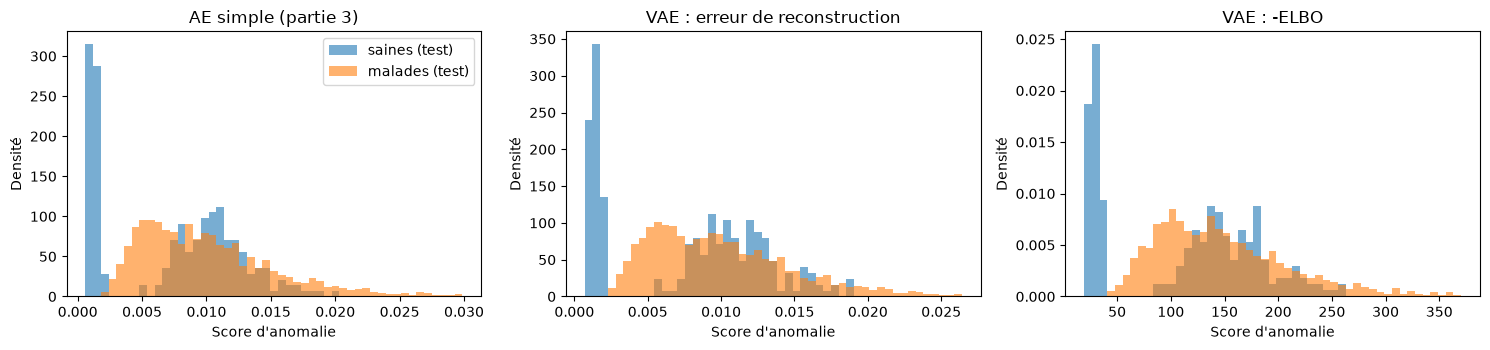

In [9]:
noms = ["AE simple (partie 3)", "VAE : erreur de reconstruction", "VAE : -ELBO"]
plt.figure(figsize=(15, 3.6))
for i in range(3):
    nom = noms[i]
    s_test = scores[nom][1]
    saines = s_test[~malade_test]
    malades = s_test[malade_test]
    bins = np.linspace(s_test.min(), np.quantile(s_test, 0.99), 50)
    plt.subplot(1, 3, i + 1)
    plt.hist(saines, bins, alpha=0.6, density=True, label="saines (test)")
    plt.hist(malades, bins, alpha=0.6, density=True, label="malades (test)")
    plt.title(nom)
    plt.xlabel("Score d'anomalie")
    plt.ylabel("Densité")
    if i == 0:
        plt.legend()
plt.tight_layout()
savefig("05_hist_vae_vs_ae.png")
plt.show()

### Comparaison VAE / auto-encodeur simple

| Score | AUROC test | Rappel maladies | Fausses alarmes |
|---|---|---|---|
| AE simple (partie 3) | 0,628 | 0,201 | 0,084 |
| VAE : erreur de reconstruction | 0,610 | 0,158 | 0,080 |
| VAE : −ELBO | 0,628 | 0,176 | 0,080 |

- La ligne de l'auto-encodeur simple retrouve exactement les chiffres de la partie 3 (0,6277, 0,2011, 0,0837) : notre calcul est bien le même que celui de Maguette.
- **L'erreur de reconstruction seule du VAE fait moins bien** que l'auto-encodeur simple (AUROC 0,610 contre 0,628). Le VAE reconstruit plus flou, à cause du bruit ajouté sur $z$ et du terme KL qui le régularise : son erreur est plus grande pour toutes les feuilles, saines comprises, et la séparation est moins nette.
- **Avec −ELBO, le VAE remonte au niveau de l'auto-encodeur** (AUROC 0,628). Le terme KL apporte donc une information en plus : le code d'une feuille malade est en moyenne un peu plus loin de la loi normale apprise sur les feuilles saines. Mais au seuil choisi, il détecte un peu moins de maladies (17,6 % contre 20,1 %).
- Les histogrammes montrent la même chose pour les trois scores : un pic très net de feuilles saines bien reconstruites, puis une grande zone où saines et malades se mélangent. Le choix du modèle (AE ou VAE) ne change pas ce problème de fond.

## Prolongement : choix de β et score d'anomalie (terme KL)

Dans la comparaison précédente, β montait de 0 à 1 et on n'a regardé que la reconstruction et −ELBO. Ici on pousse la question plus loin, **sur la validation uniquement** :

- trois VAE entraînés sur les saines avec un β **fixe** (0,1 ; 1 ; 4), k = 32, 40 époques ;
- trois scores possibles : erreur de reconstruction (`mse`), terme KL seul (`kl`) et −ELBO (`elbo`) ;
- on garde la meilleure combinaison (β, score) selon l'AUROC de validation, puis on l'évalue **une seule fois** sur le test, avec le même seuil (95e centile des saines de validation).

In [10]:
import time
from src.models import vae_loss
from sklearn.metrics import roc_auc_score

dev = C.DEVICE
healthy = C.HEALTHY_CLASS
diseased = [c for c in D.CLASSES if c != healthy]

def load(split, classes):
    """Images 64x64 d'un split -> tenseur (N, 3, 64, 64) dans [0, 1]."""
    d = D.subset(df, split=split, classes=classes)
    imgs = D.load_cache([C.resolve(p) for p in d["path"]], C.AE_SIZE)
    return torch.from_numpy(np.array(imgs)).permute(0, 3, 1, 2).float().div(255).to(dev)

X_train = load("train", [healthy])
X_val_h = load("val", [healthy])
X_val_d = load("val", diseased)
print("healthy (train) :", tuple(X_train.shape), "| healthy (val) :", tuple(X_val_h.shape), "| diseased (val) :", tuple(X_val_d.shape))

healthy (train) : (1115, 3, 64, 64) | healthy (val) : (237, 3, 64, 64) | diseased (val) : (2487, 3, 64, 64)


In [11]:
K_BETA = 32
EPOCHS, BATCH, LR = 40, 64, 1e-3
BETAS = [0.1, 1.0, 4.0]
D_PIXELS = 3 * 64 * 64

def train_vae(beta):
    """Entraîne un VAE sur les feuilles saines. Renvoie le modèle, l'historique et la durée."""
    C.set_seed(42)
    t0 = time.time()
    model = VAE(K_BETA).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"rec": [], "kl": [], "val_rec": [], "val_kl": []}
    for ep in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X_train), device=dev)
        rec_s, kl_s = 0.0, 0.0
        for i in range(0, len(order), BATCH):
            x = X_train[order[i:i + BATCH]]
            if torch.rand(1) < 0.5: x = x.flip(3)
            if torch.rand(1) < 0.5: x = x.flip(2)
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            rec_s += rec.item() * len(x); kl_s += kl.item() * len(x)
        model.eval()
        with torch.no_grad():
            x_hat, mu, logvar = model(X_val_h)          # en évaluation, z = mu
            _, vr, vk = vae_loss(x_hat, X_val_h, mu, logvar, beta)
        hist["rec"].append(rec_s / len(X_train)); hist["kl"].append(kl_s / len(X_train))
        hist["val_rec"].append(vr.item()); hist["val_kl"].append(vk.item())
        if (ep + 1) % 10 == 0:
            print(f"beta={beta} epoch {ep + 1}/{EPOCHS}  rec val {vr.item():.1f}  KL val {vk.item():.1f}")
    return model, hist, time.time() - t0

vaes, hists, times = {}, {}, {}
for b in BETAS:
    vaes[b], hists[b], times[b] = train_vae(b)
    print(f"-> beta={b} : {times[b]:.0f} s")

beta=0.1 epoch 10/40  rec val 85.9  KL val 92.5


beta=0.1 epoch 20/40  rec val 78.9  KL val 75.0


beta=0.1 epoch 30/40  rec val 73.6  KL val 68.9


beta=0.1 epoch 40/40  rec val 74.2  KL val 67.3
-> beta=0.1 : 23 s


beta=1.0 epoch 10/40  rec val 103.8  KL val 24.4


...

beta=1.0 epoch 40/40  rec val 80.9  KL val 21.7
-> beta=1.0 : 23 s


beta=4.0 epoch 10/40  rec val 147.7  KL val 5.4


beta=4.0 epoch 20/40  rec val 129.6  KL val 5.7


beta=4.0 epoch 30/40  rec val 118.0  KL val 5.7


beta=4.0 epoch 40/40  rec val 113.6  KL val 5.9
-> beta=4.0 : 23 s


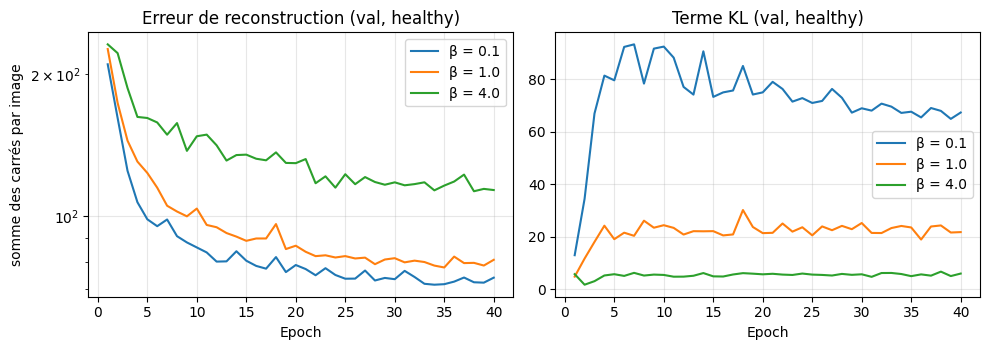

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for b in BETAS:
    ax[0].plot(range(1, EPOCHS + 1), hists[b]["val_rec"], label=f"β = {b}")
    ax[1].plot(range(1, EPOCHS + 1), hists[b]["val_kl"], label=f"β = {b}")
ax[0].set_yscale("log"); ax[0].set_title("Erreur de reconstruction (val, healthy)"); ax[0].set_ylabel("somme des carrés par image")
ax[1].set_title("Terme KL (val, healthy)")
for a in ax:
    a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_beta_courbes.png", dpi=150, bbox_inches="tight"); plt.show()

### Reconstructions et images générées

- Ligne du haut : feuilles saines de la validation. Lignes suivantes : leur reconstruction par le VAE de chaque β.
- Dernières lignes : feuilles **inventées**, obtenues en décodant un `z` tiré au hasard dans une loi normale. Aucune image réelle n'est utilisée.

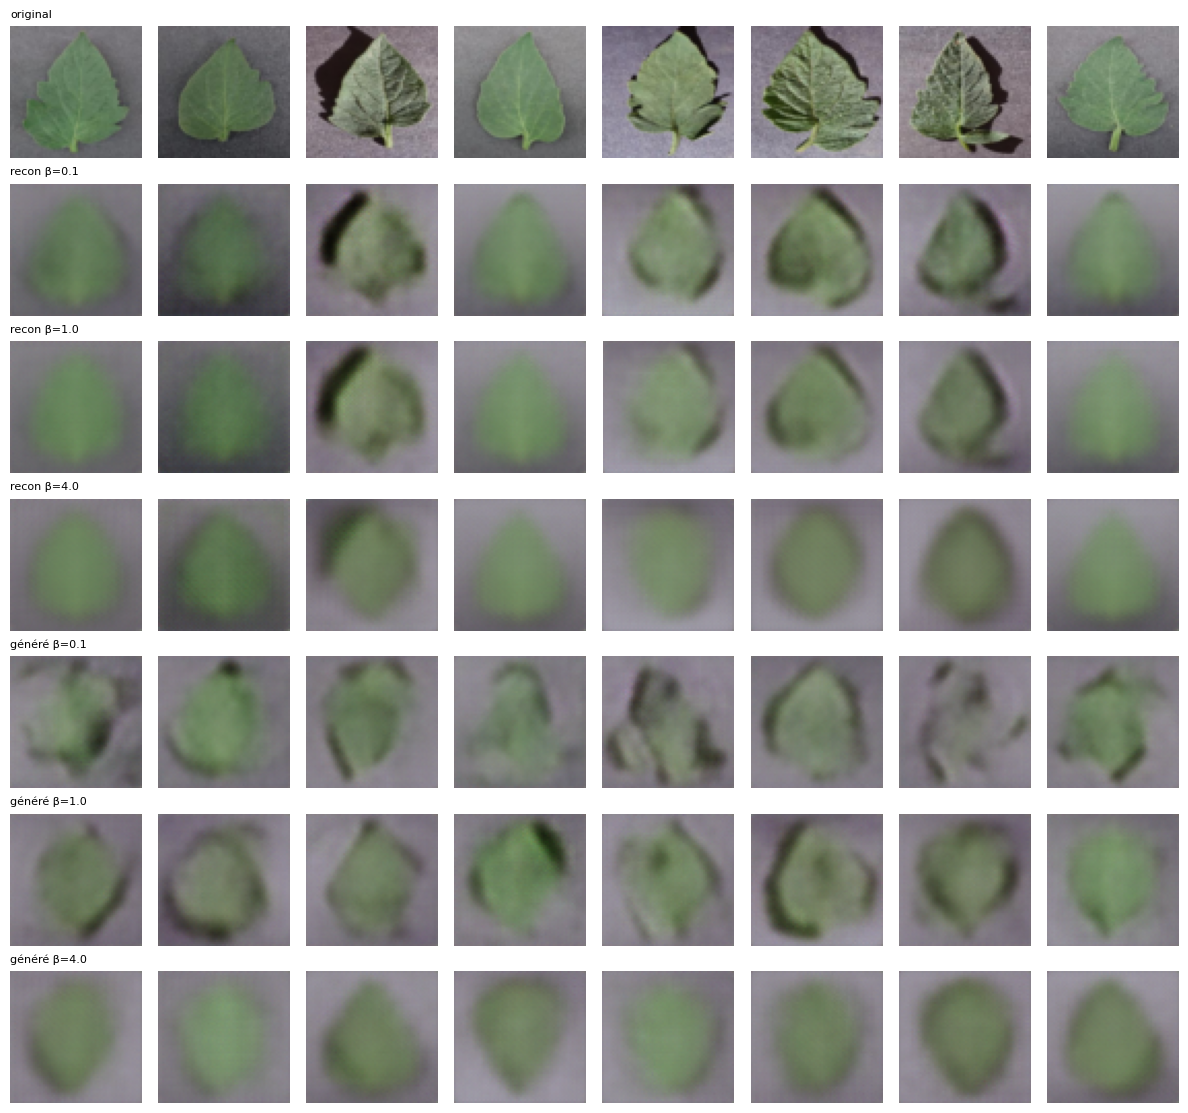

In [13]:
idx = np.linspace(0, len(X_val_h) - 1, 8).astype(int)
x = X_val_h[idx]
lignes = [("original", x)]
with torch.no_grad():
    for b in BETAS:
        lignes.append((f"recon β={b}", vaes[b].eval()(x)[0]))
torch.manual_seed(42)
for b in BETAS:
    lignes.append((f"généré β={b}", vaes[b].eval().sample(8, dev)))

fig, ax = plt.subplots(len(lignes), 8, figsize=(8 * 1.5, len(lignes) * 1.6))
for r, (nom, imgs) in enumerate(lignes):
    for c in range(8):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis("off")
    ax[r, 0].set_title(nom, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_vae_recon_generation.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe

- **Reconstruction.** Plus β est grand, plus les images sont floues : l'erreur de reconstruction de validation finit à 74 (β = 0,1), 81 (β = 1) et 114 (β = 4). Le terme KL fait l'inverse, 67, 22 puis 5,9. C'est le compromis attendu.
- **Détail perdu.** Les feuilles reviennent sous forme de taches vertes lisses : la forme, la couleur et l'arrière-plan sont conservés, mais les nervures et les motifs de la surface disparaissent. Les zones noires sur les bords de certaines photos (arrière-plan de la photo, pas la feuille) sont reproduites floues.
- **Génération.** Avec β = 0,1, les feuilles inventées sont déchirées et irrégulières : l'espace latent n'est pas assez régulier pour qu'un `z` tiré au hasard tombe dans une zone qui ressemble à une vraie feuille. Avec β = 1, elles ressemblent à des feuilles floues, plus compactes, parfois avec un bord sombre. Avec β = 4, ce sont des taches vertes qui se ressemblent beaucoup : il y a peu de diversité d'une image à l'autre.
- **Ce qu'on retient.** Aucune de ces images n'est réaliste : à 64×64 et avec une perte au carré, un VAE donne des images floues. À notre avis, β = 1 est le meilleur compromis visuel (jugement visuel, pas une mesure).

### Choix de β et du score d'anomalie (sur la validation)

Un VAE donne trois scores possibles pour dire « cette feuille est anormale » :
- `mse` : erreur de reconstruction moyenne par pixel (comme l'auto-encodeur de la partie 3) ;
- `kl` : distance entre le code de l'image et la loi normale ;
- `elbo` : reconstruction + β × KL, c'est-à-dire la perte d'entraînement de l'image.

On calcule l'AUROC malade contre saine pour chaque β et chaque score, sur la **validation**, et on garde la meilleure combinaison.

In [14]:
@torch.no_grad()
def vae_scores(model, X, beta):
    """Scores par image : mse (par pixel), kl, elbo = somme des carrés + beta·KL."""
    model.eval()
    mse, kl = [], []
    for i in range(0, len(X), 256):
        xb = X[i:i + 256]
        x_hat, mu, logvar = model(xb)
        mse.append(((x_hat - xb) ** 2).flatten(1).mean(1))
        kl.append(-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    mse, kl = torch.cat(mse).cpu().numpy(), torch.cat(kl).cpu().numpy()
    return {"mse": mse, "kl": kl, "elbo": mse * D_PIXELS + beta * kl}

def auroc(s_saines, s_malades):
    y = np.r_[np.zeros(len(s_saines)), np.ones(len(s_malades))]
    return roc_auc_score(y, np.r_[s_saines, s_malades])

auc_val = {}
print(f"{'β':>5s} {'mse':>7s} {'kl':>7s} {'elbo':>7s}   (AUROC validation)")
for b in BETAS:
    sh, sd = vae_scores(vaes[b], X_val_h, b), vae_scores(vaes[b], X_val_d, b)
    for nom in ("mse", "kl", "elbo"):
        auc_val[(b, nom)] = auroc(sh[nom], sd[nom])
    print(f"{b:>5} {auc_val[(b, 'mse')]:>7.3f} {auc_val[(b, 'kl')]:>7.3f} {auc_val[(b, 'elbo')]:>7.3f}")

BETA_BEST, SCORE_BEST = max(auc_val, key=auc_val.get)      # choix sur la validation uniquement
vae_beta = vaes[BETA_BEST]
print(f"Choix : β = {BETA_BEST}, score = {SCORE_BEST} (AUROC val {auc_val[(BETA_BEST, SCORE_BEST)]:.3f})")

    β     mse      kl    elbo   (AUROC validation)


  0.1   0.599   0.825   0.608


  1.0   0.629   0.779   0.661


  4.0   0.652   0.790   0.700
Choix : β = 0.1, score = kl (AUROC val 0.825)


### Ce qu'on observe

| β | mse | kl | elbo |
|---|---|---|---|
| 0,1 | 0,599 | **0,825** | 0,608 |
| 1 | 0,629 | 0,779 | 0,661 |
| 4 | 0,652 | 0,790 | 0,700 |

- **Le meilleur score est le terme KL**, avec β = 0,1 (AUROC validation 0,825). Il est bien meilleur que l'erreur de reconstruction (0,599 à 0,652), qui est le score de la partie 3 (AUROC validation 0,634 pour l'auto-encodeur).
- **L'erreur de reconstruction détecte moins bien quand β est petit.** Avec β = 0,1, le VAE reconstruit mieux toutes les images (erreur de validation la plus basse, 74), y compris les malades : c'est une explication possible de l'AUROC plus faible du score `mse`, que nous n'avons pas vérifiée.
- **Pourquoi le KL marche mieux : une hypothèse, pas vérifiée.** Le KL mesure à quel point le code d'une image est loin de ce que le VAE a appris sur les feuilles saines. Il réagit peut-être à ce que les feuilles malades ont de différent (texture, couleur, fond), pas seulement à la difficulté de les reconstruire. On n'a pas testé si c'est la lésion ou le fond qui compte.
- **Choix.** β = 0,1 et le score KL sont choisis sur la validation pour la détection. Le β le plus joli pour la génération (β = 1) n'est donc pas celui qu'on garde pour détecter : les deux objectifs ne vont pas ensemble.

### Le VAE comme détecteur d'anomalies, comparé à l'auto-encodeur simple

- Même protocole que la partie 3 : seuil = 95e centile du score des feuilles saines de validation, c'est-à-dire environ 5 % de fausses alarmes attendues.
- L'auto-encodeur de référence est celui de la partie 3 (k = 16, `ae_best.pt`), avec son erreur de reconstruction.
- **C'est ici qu'on regarde le test, une seule fois.**

In [15]:
@torch.no_grad()
def ae_scores(X):
    return torch.cat([((ae_sain(X[i:i + 256]) - X[i:i + 256]) ** 2).mean(dim=(1, 2, 3)) for i in range(0, len(X), 256)]).cpu().numpy()

def score_vae(X):
    return vae_scores(vae_beta, X, BETA_BEST)[SCORE_BEST]

systemes = {"AE simple (k=16)": ae_scores, f"VAE (β={BETA_BEST}, {SCORE_BEST})": score_vae}
seuils = {nom: float(np.percentile(f(X_val_h), 95)) for nom, f in systemes.items()}
print("Seuils (95e centile des saines de validation) :", {k: round(v, 5) for k, v in seuils.items()})

X_test_h = load("test", [healthy])
test_malades = {c: load("test", [c]) for c in diseased}
X_test_d = torch.cat(list(test_malades.values()))

resultats = {}
for nom, f in systemes.items():
    sh, sd = f(X_test_h), f(X_test_d)
    resultats[nom] = {"auroc": auroc(sh, sd), "rappel": float((sd > seuils[nom]).mean()), "fausses_alarmes": float((sh > seuils[nom]).mean()),
                      "rappel_maladie": {D.short(c): float((f(X) > seuils[nom]).mean()) for c, X in test_malades.items()}}

print(f"{'système':>26s} {'AUROC':>7s} {'rappel malades':>15s} {'fausses alarmes':>16s}")
for nom, r in resultats.items():
    print(f"{nom:>26s} {r['auroc']:>7.3f} {r['rappel']:>15.3f} {r['fausses_alarmes']:>16.3f}")

Seuils (95e centile des saines de validation) : {'AE simple (k=16)': 0.01405, 'VAE (β=0.1, kl)': 93.17198}


                   système   AUROC  rappel malades  fausses alarmes
          AE simple (k=16)   0.628           0.201            0.084
           VAE (β=0.1, kl)   0.822           0.502            0.071


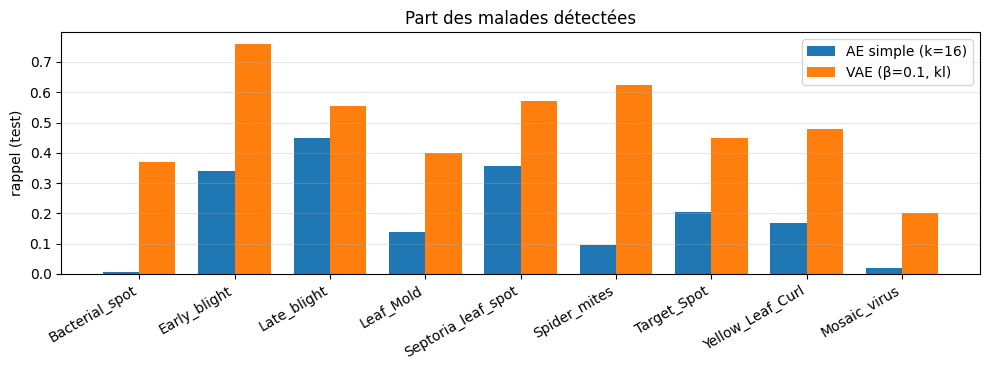

In [16]:
maladies = list(next(iter(resultats.values()))["rappel_maladie"])
x = np.arange(len(maladies))
plt.figure(figsize=(10, 3.8))
for i, (nom, r) in enumerate(resultats.items()):
    plt.bar(x + (i - .5) * .38, [r["rappel_maladie"][m] for m in maladies], .38, label=nom)
plt.xticks(x, maladies, rotation=30, ha="right"); plt.ylabel("rappel (test)")
plt.title("Part des malades détectées"); plt.legend(); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(C.FIG_DIR / "05_rappel_par_maladie.png", dpi=150, bbox_inches="tight"); plt.show()

### Ce qu'on observe sur le test

| Système | AUROC | Rappel malades | Fausses alarmes |
|---|---|---|---|
| AE simple (k = 16) | 0,628 | 0,201 | 0,084 |
| VAE (β = 0,1, KL) | **0,822** | **0,502** | **0,071** |

- **Le VAE détecte deux fois et demie plus de malades** (50,2 % contre 20,1 %) avec un peu moins de fausses alarmes (7,1 % contre 8,4 %), et son AUROC passe de 0,63 à 0,82. Les valeurs de validation (0,825) et de test (0,822) sont très proches : le choix de β et du score n'est pas sur-ajusté.
- **Le gain est général** : le VAE fait mieux que l'auto-encodeur sur les 9 maladies, surtout sur Bacterial_spot (de 0 à 0,37), Spider_mites (de 0,10 à 0,63) et Early_blight (de 0,34 à 0,76). Les maladies les moins détectées restent Mosaic_virus (0,20), Bacterial_spot (0,37) et Leaf_Mold (0,40).
- **Cela reste insuffisant seul** : la moitié des feuilles malades passent encore sous le seuil. Comme à la partie 3, un détecteur de ce type ne peut pas remplacer un classifieur ; il peut servir de signal complémentaire.
- **Réserve.** Le seuil du VAE (93) est exprimé en unités de KL, donc il dépend de β : un autre β donnerait un autre seuil. **Les résultats varient d'une exécution à l'autre** : une première exécution de ce même code, dans un notebook où ce prolongement tournait seul, donnait AUROC test 0,80, rappel 39,7 % et 8,4 % de fausses alarmes. L'ordre des cellules et le matériel changent légèrement l'entraînement, même avec la graine 42. L'ordre de grandeur (AUROC autour de 0,8, loin des 0,63 de l'auto-encodeur) est stable, pas la deuxième décimale.

In [17]:
nom_vae = f"VAE (β={BETA_BEST}, {SCORE_BEST})"
r = resultats[nom_vae]
torch.save({"model": vae_beta.state_dict(), "meta": {"type": "vae", "k": K_BETA, "beta": BETA_BEST, "score": SCORE_BEST}}, C.CKPT_DIR / "vae_best.pt")
C.save_json({"beta": BETA_BEST, "score": SCORE_BEST, "k": K_BETA, "threshold_p95": seuils[nom_vae],
             "auroc_val": {f"{b}_{s}": a for (b, s), a in auc_val.items()}}, C.RESULTS / "thresholds_vae.json")

taille = sum(t.numel() * t.element_size() for t in vae_beta.state_dict().values()) / 1e6
upsert_summary({"experiment": f"P5_VAE_k{K_BETA}", "partie": 5, "modele": "VAE",
                "hyperparametres": f"k = {K_BETA}, β = {BETA_BEST}, score {SCORE_BEST}, Adam lr={LR}, batch {BATCH}, {EPOCHS} époques",
                "resolution": 64, "params": sum(p.numel() for p in vae_beta.parameters()), "taille_mo": round(taille, 2),
                "temps_entrainement_s": round(times[BETA_BEST], 1),
                "test_auroc": round(r["auroc"], 4), "test_rappel_anomalies": round(r["rappel"], 4),
                "test_fausses_alarmes": round(r["fausses_alarmes"], 4)})
print("Ligne P5_VAE ajoutée à results/summary.csv")

Ligne P5_VAE ajoutée à results/summary.csv


## Conclusion de la partie 5

Le VAE fait bien ce qu'on attend d'un modèle génératif : un espace latent continu, des interpolations régulières et de nouvelles images plausibles. Mais à 64×64 et avec k = 32, il ne garde que la couleur, la forme et le fond. Les lésions, qui sont justement ce qui distingue les maladies, sont perdues. Comme détecteur d'anomalies, avec β qui monte jusqu'à 1, il n'apporte rien de plus que l'auto-encodeur simple : −ELBO fait jeu égal en AUROC, et l'erreur seule fait moins bien. Le prolongement ci-dessus nuance ce constat : avec un β plus petit (0,1), le terme KL seul détecte nettement mieux (AUROC test 0,82, rappel 50,2 % pour 7,1 % de fausses alarmes ; 0,80 dans une première exécution), mais ce VAE génère de moins bonnes images.

Cela confirme la conclusion des parties 3 et 4 : un modèle qui reconstruit l'image entière est surtout sensible à l'apparence globale (couleur, fond, éclairage), pas aux petits détails de la maladie. Le bon score du terme KL ne dit pas non plus si le VAE réagit à la lésion ou au fond : nous ne l'avons pas testé. Pour mieux faire, il faudrait des images plus grandes, un score calculé seulement sur la feuille (avec le masque de la partie 6), ou une perte qui garde mieux les détails que la MSE.